In [ ]:
# Paths: set DATA_DIR / OUTPUT_DIR as environment variables, or edit the defaults below.
import os
DATA_DIR = os.environ.get("DATA_DIR", "../data")


In [1]:
pass  # Colab only: from google.colab import drive
pass  # Colab only: drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import requests, zipfile, io, os
import pandas as pd
import numpy as np
import joblib
import lightgbm as lgb
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

In [3]:
BASE_DIR     = DATA_DIR + "/"
DATASETS_DIR = BASE_DIR + "datasets/"
NATIONAL_DIR = BASE_DIR + "national/"
MODELS_DIR   = BASE_DIR + "models/"

AADF_PATH = DATASETS_DIR + "aadf_major_roads.csv"

In [7]:
#Load data
grid        = pd.read_csv(NATIONAL_DIR + 'national_grid_with_volume.csv')
collisions  = pd.read_csv(DATASETS_DIR + 'collisions_features.csv',
                          dtype={'collision_index': str}, low_memory=False)
collisions['datetime'] = pd.to_datetime(collisions['datetime'])
print(f"Grid: {len(grid):,} cells | Collisions: {len(collisions):,}")

Grid: 43,903 cells | Collisions: 503,407


In [8]:
#Attach grid history + volume to every collision
collisions['grid_lat'] = collisions['latitude'].round(2)
collisions['grid_lon'] = collisions['longitude'].round(2)
collisions['grid_id']  = (collisions['grid_lat'].astype(str) + '_' +
                           collisions['grid_lon'].astype(str))

merge_cols = [
    'grid_id', 'base_risk_score', 'log_freq', 'serious_rate',
    'hist_freq_score', 'hist_severity_score',
    'pct_dark', 'pct_wet', 'pct_rural', 'pct_high_speed',
    # New volume features
    'log_aadf', 'hgv_pct', 'acc_per_mvkm',
    'log_aadf_norm', 'hgv_pct_norm', 'acc_per_mvkm_norm',
    'aadf_matched'
]

df = collisions.merge(grid[merge_cols], on='grid_id', how='left')

# Fill unmatched with medians
for col in merge_cols[1:]:
    df[col] = df[col].fillna(grid[col].median())

print(f"Matched: {df['base_risk_score'].notna().sum():,}")

Matched: 503,407


In [9]:
#Encode categoricals
le_time    = LabelEncoder()
le_season  = LabelEncoder()
le_surface = LabelEncoder()
df['time_bucket_enc'] = le_time.fit_transform(df['time_bucket'])
df['season_enc']      = le_season.fit_transform(df['season'])
df['surface_enc']     = le_surface.fit_transform(df['surface_label'])

In [10]:
#target
df['target_risk'] = (
    0.6 * df['log_freq'] / df['log_freq'].max() +
    0.4 * df['is_serious'].astype(float)
)

In [11]:
#Feature matrix — now includes volume features
feature_cols = [
    # Temporal
    'hour','day_of_week','month','time_bucket_enc','season_enc',
    'is_weekend','is_rush_hour','friday_evening',
    # Conditions
    'is_dark','is_dark_no_lights','light_conditions',
    'is_wet_road','is_icy_road','is_bad_weather',
    'surface_enc','weather_conditions',
    # Road properties
    'speed_limit','road_type','urban_or_rural_area',
    'is_dual_carriageway','is_high_speed','is_rural_road',
    'at_junction','junction_detail',
    # Interactions
    'dark_and_wet','high_speed_and_dark','high_speed_and_wet',
    'rural_and_dark','dark_and_no_lights',
    # Historical segment risk (v3 features)
    'base_risk_score','log_freq','serious_rate',
    'hist_freq_score','hist_severity_score',
    'pct_dark','pct_wet','pct_rural','pct_high_speed',
    # NEW: Traffic volume features
    'log_aadf','hgv_pct','acc_per_mvkm',
    'log_aadf_norm','hgv_pct_norm','acc_per_mvkm_norm',
    'aadf_matched',
]

X = df[feature_cols].fillna(0)
y = df['target_risk']

In [12]:
#Time-based train/test split
train_mask = df['datetime'].dt.year <= 2022
test_mask  = df['datetime'].dt.year >= 2023
X_train, y_train = X[train_mask], y[train_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]
print(f"\nTrain: {len(X_train):,} | Test: {len(X_test):,}")


Train: 298,237 | Test: 205,170


In [13]:
#Train LightGBM v4
model_v4 = lgb.LGBMRegressor(
    n_estimators      = 1000,
    learning_rate     = 0.02,
    max_depth         = 6,
    num_leaves        = 31,
    min_child_samples = 20,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    reg_alpha         = 0.1,
    reg_lambda        = 0.1,
    random_state      = 42,
    verbose           = -1
)

model_v4.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(50, verbose=False),
               lgb.log_evaluation(200)]
)

[200]	valid_0's l2: 0.0264549
[400]	valid_0's l2: 0.0263234
[600]	valid_0's l2: 0.0262837
[800]	valid_0's l2: 0.026268
[1000]	valid_0's l2: 0.0262521


LGBMRegressor(colsample_bytree=0.8, learning_rate=0.02, max_depth=6,
              n_estimators=1000, random_state=42, reg_alpha=0.1, reg_lambda=0.1,
              subsample=0.8, verbose=-1)

In [14]:
#Evaluate
y_pred = model_v4.predict(X_test)
mae    = mean_absolute_error(y_test, y_pred)
r2     = r2_score(y_test, y_pred)

print(f"\nModel Performance ")
print(f"MAE:  {mae:.4f}  (v3 national baseline: 0.1283)")
print(f"R²:   {r2:.4f}  (v3 national baseline: 0.4106)")
print(f"Predicted range: {y_pred.min():.3f} → {y_pred.max():.3f}")



Model Performance 
MAE:  0.1282  (v3 national baseline: 0.1283)
R²:   0.4087  (v3 national baseline: 0.4106)
Predicted range: 0.001 → 0.719



 Top 15 Features
            feature  importance
       serious_rate        4312
    base_risk_score        2823
               hour        2095
           log_freq        1791
           log_aadf        1532
            hgv_pct        1453
            pct_wet        1232
       acc_per_mvkm        1057
           pct_dark        1054
          road_type        1024
        speed_limit        1005
              month        1001
     pct_high_speed         966
hist_severity_score         888
        day_of_week         838

 Volume feature ranks 
  log_aadf             rank #39  importance=1,532
  hgv_pct              rank #40  importance=1,453
  acc_per_mvkm         rank #41  importance=1,057
  log_aadf_norm        rank #42  importance=297
  hgv_pct_norm         rank #43  importance=351
  acc_per_mvkm_norm    rank #44  importance=220
  aadf_matched         rank #45  importance=32


<Figure size 1000x800 with 0 Axes>

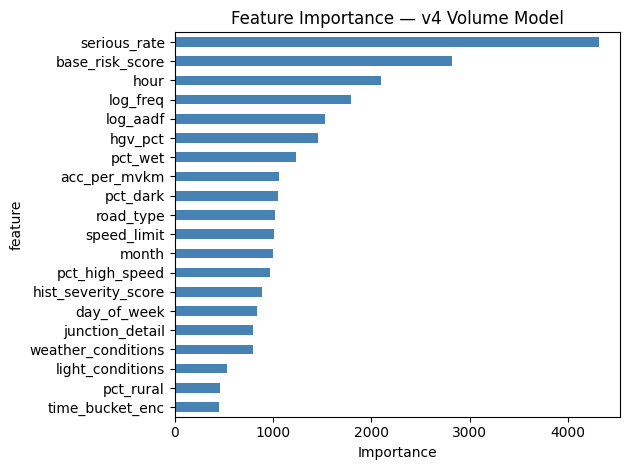

In [15]:
#Feature importance
importance = pd.DataFrame({
    'feature':    feature_cols,
    'importance': model_v4.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n Top 15 Features")
print(importance.head(15).to_string(index=False))

# Highlight volume feature positions
volume_features = ['log_aadf','hgv_pct','acc_per_mvkm',
                   'log_aadf_norm','hgv_pct_norm','acc_per_mvkm_norm','aadf_matched']
print(f"\n Volume feature ranks ")
for vf in volume_features:
    rank = importance[importance['feature']==vf].index[0] + 1
    imp  = importance[importance['feature']==vf]['importance'].values[0]
    print(f"  {vf:20s} rank #{rank:2d}  importance={imp:,}")

plt.figure(figsize=(10, 8))
importance.head(20).plot(kind='barh', x='feature', y='importance',
                          legend=False, color='steelblue')
plt.title('Feature Importance — v4 Volume Model')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(NATIONAL_DIR + 'feature_importance_v4.png', dpi=150)
plt.show()

In [20]:
#Save
joblib.dump(model_v4,   MODELS_DIR + 'risk_model_v4_volume.pkl')
joblib.dump(le_time,    MODELS_DIR + 'le_time.pkl')
joblib.dump(le_season,  MODELS_DIR + 'le_season.pkl')
joblib.dump(le_surface, MODELS_DIR + 'le_surface.pkl')

import json
with open(MODELS_DIR + 'feature_cols_v4.json', 'w') as f:
    json.dump(feature_cols_v4_clean, f)

print("\n v4 volume model saved as risk_model_v4_volume.pkl")


 v4 volume model saved as risk_model_v4_volume.pkl
